# Kontrollstrukturen

::: {.callout-note}
### Lernziele {.unnumbered}
Nach diesem Kapitel können Sie …

- Verzweigungen mit `if`, `elif` und `else` sowie Conditional Expressions formulieren
- Bedingungen mit `and`, `or` und `not` verknüpfen
- Wiederholungen mit `while`- und `for`-Schleifen umsetzen und den passenden Schleifentyp wählen
- den Schleifenablauf mit `break` und `continue` steuern
- verschachtelte Schleifen schreiben
- einfache mathematische Verfahren (Newton-Verfahren, Vektor- und Matrixrechnung) mit Schleifen umsetzen
:::

In der Programmierung sind Kontrollstrukturen essenziell, um den Ablauf eines Programms zu steuern. Sie ermöglichen es, Entscheidungen zu treffen, Wiederholungen durchzuführen und den Programmfluss gezielt zu lenken. Ohne sie würden Programme einfach nur von oben nach unten ausgeführt werden, ohne auf Eingaben oder Bedingungen zu reagieren.

Wir unterscheiden zwischen zwei grundsätzlichen Arten von Kontrollstrukturen: **Verzweigungen** und **Schleifen**.

## Verzweigungen

Verzweigungen oder bedingte Anweisungen sind nichts anderes als Fallunterscheidungen: "Wenn eine bestimmte Bedingung erfüllt ist, tue dies, andernfalls tue das." In den meisten Programmiersprachen wird dies durch eine `if`-Anweisung realisiert (die genaue Syntax unterscheidet sich von Sprache zu Sprache). Das folgende Codebeispiel zeigt, wie es in Python funktioniert:

In [1]:
number = 42

if number > 0:
    print("Die Zahl ist positiv!")

Die Zahl ist positiv!


In diesem einfachen Beispiel wird die Bedingung `number > 0` geprüft. Ist die Bedingung erfüllt, werden die **eingerückten** Anweisungen ausgeführt, in diesem Beispiel der `print`-Befehl. 

Die Funktionsweise einer `if`-Anweisung lässt sich mit einem Flussdiagramm (@fig-if) anschaulich darstellen.

![Flussdiagramm zur if-Anweisung](images/if.png){#fig-if width=288px}

Wichtig ist die korrekte Syntax: Die Anweisung wird mit dem Schlüsselwort `if` eingeleitet, gefolgt von der Bedingung und einem Doppelpunkt. Alle Anweisungen, die bei erfüllter Bedingung ausgeführt werden sollen, müssen darunter eingerückt sein. Wir betrachten ein zweites Beispiel:  

In [18]:
max_load = 5000  # Maximale Belastung in Newton
current_load = float(input("Belastung in Newton: "))  # z.B. ein Messergebnis

if current_load > max_load:
    print("Warnung: Belastung überschritten!")
    factor = (current_load - max_load) / max_load
    print(f"Maximale Belastung um {round(100*factor, 2)} % überschritten!")

Belastung in Newton:  5200


Warnung: Belastung überschritten!
Maximale Belastung um 4.0 % überschritten!


Aktuell beschränken sich unsere Beispiele zu Zwecken der Illustration auf simple Ausgaben, aber natürlich gibt es keine Grenzen für die Komplexität, die in einem `if`-Block ausgeführt werden kann.  

### Verzweigungen mit if und else {.unnumbered}
In den meisten Fällen verwendet man erweiterte Varianten der `if`-Anweisung. Zum Beispiel möchte man auch bestimmte Anweisungen ausführen, falls die Bedingung nicht erfüllt ist. Dafür ergänzt man einen `else`-Block:

In [20]:
max_load = 5000  # Maximale Belastung in Newton
current_load = float(input("Belastung in Newton: "))

if current_load > max_load:
    print("Warnung: Belastung überschritten!")
    factor = (current_load - max_load) / max_load
    print(f"Maximale Belastung um {round(100*factor, 2)} % überschritten!")
else:
    print("Alles im grünen Bereich!")

Belastung in Newton:  4600


Alles im grünen Bereich!


Auch diese Variante stellen wir im Flussdiagramm dar (@fig-ifelse). 

![Flussdiagramm zur Verzweigung mit if und else](images/ifelse.png){#fig-ifelse width=336px}

Wir haben die Flussdiagramme bewusst so gezeichnet, dass die Einrückungen, wie sie von Python verlangt werden, auch im Diagramm ersichtlich sind: Die Schlüsselwörter `if` und `else` befinden sich untereinander auf derselben Einrückungsebene, die jeweiligen Anweisungsblöcke sind darunter eingerückt.  

::: {.callout-warning}
### Fallstrick: Gleitkommazahlen mit `==` vergleichen {.unnumbered}
```python
x = 0.1 + 0.2
if x == 0.3:
    print("gleich")
else:
    print("ungleich")   # wird ausgegeben!
```

Wie im Kapitel *Datentypen* gezeigt, können Gleitkommazahlen viele Dezimalzahlen nicht exakt darstellen: `0.1 + 0.2` ergibt `0.30000000000000004`. In Bedingungen sollte man Gleitkommazahlen deshalb nicht mit `==` vergleichen, sondern prüfen, ob sie *nahe genug* beieinanderliegen:

```python
if abs(x - 0.3) < 1e-9:   # Abweichung kleiner als eine Toleranz
    print("gleich")
```

Alternativ verwenden Sie `math.isclose(x, 0.3)` aus dem Modul `math` (siehe Kapitel *Datentypen*).
:::

### Verzweigungen mit if, elif und else {.unnumbered}
Schließlich können wir unsere Verzweigung noch um sog. "else-if-Zweige" erweitern (das Python-Keyword heißt `elif`). Der Sinn davon: Wenn eine erste Bedingung falsch ist, möchte man vielleicht eine weitere Bedingung prüfen. Ist auch diese falsch, könnte noch eine dritte (vierte, fünfte, ...) Bedingung interessant sein. In Worten: "Wenn Bedingung1 wahr ist, tue A, andernfalls prüfe Bedingung2. Ist Bedingung2 wahr, tue B, andernfalls prüfe Bedingung3 usw." Wichtig zu verstehen ist, dass die Bedingungen nacheinander geprüft werden. Wenn eine frühere Bedingung bereits erfüllt ist, werden spätere Bedingungen gar nicht mehr angeschaut. Ein (optionales) finales `else` fängt den Fall auf, wenn keine Bedingung erfüllt ist. Das Flussdiagramm @fig-elif stellt die möglichen Fälle dar. Es können beliebig viele `elif`-Blöcke verwendet werden und das finale `else` kann auch weggelassen werden. Damit steht uns eine sehr flexible Möglichkeit für Verzweigungen zur Verfügung.

![Flussdiagramm zur Verzweigung mit if, elif und else](images/elif.png){#fig-elif width=546px}

In [22]:
# Grenzwerte für die Motorüberwachung (in °C)
normal_temp = 80  # normale Betriebstemperatur
warning_temp = 100  # Warnschwelle
danger_temp = 120  # kritische Temperatur

# Eingabe: gemessene Motortemperatur
temperature = float(input("Aktuelle Motortemperatur in °C: "))

# Bewertung der Temperatur
if temperature < 0:
    print("Fehler: Ungültige Temperatur. Bitte Sensor prüfen.")
elif temperature <= normal_temp:
    print("Temperatur im sicheren Bereich.")
elif temperature <= warning_temp:
    print("Achtung: Temperatur erhöht. Kühlung überprüfen.")
elif temperature <= danger_temp:
    print("Kritische Warnung! Motor überhitzt!")
    #hier folgt Code, der eine zusätzliche Kühlung aktiviert
else:
    print("Motor wird abgeschaltet!")
    #hier folgt Code, der den Motor sofort abschaltet

Aktuelle Motortemperatur in °C:  110


Kritische Warnung! Motor überhitzt!


::: {.callout-note} 
### Die if-Anweisung in anderen Programmiersprachen {.unnumbered}
Die `if`-Anweisung ist ein universelles Werkzeug der Programmierung, das Sie in vielen Programmiersprachen wiederfinden werden. Beim Wechsel zu einer anderen Programmiersprache müssen Sie sich mit der jeweiligen Syntax vertraut machen. Python verpflichtet Sie z.B. zu Einrückungen, was in anderen Programmiersprachen eher unüblich ist (zu Zwecken der Übersichtlichkeit aber trotzdem gemacht wird). In C verwendet man geschweifte Klammern, um die Blöcke voneinander abzugrenzen. Hier ein Beispiel: 

```C
    int temperatur = 25;

    if (temperatur > 30) {
        printf("Es ist heiß!\n");
    } else if (temperatur > 20) {
        printf("Angenehmes Wetter.\n");
    } else {
        printf("Es ist kühl.\n");
    }
```

Sie erkennen sicherlich die große Ähnlichkeit zu dem, was Sie in Python kennengelernt haben, aber auch Unterschiede. Zum Beispiel schreibt man in C `else if` statt des verkürzten `elif`.

:::

::: {.callout-tip}
### Conditional Expressions {.unnumbered}
Python bietet außerdem die sog. Conditional Expressions (in C und verwandten Sprachen gibt es dafür den Operator `bedingung ? wert1 : wert2`). Sie sind eine elegante Art, Code kompakt darzustellen, wenn eine Zuweisung abhängig von einer `if`-Bedingung stattfinden soll. Dazu betrachten wir zunächst ein Beispiel als traditionelle Verzweigung mit `if` und `else`:
```python
if voltage > 1000:
    classification = "Hochspannung" # nach DIN VDE 0100: 1000 V AC
else:
    classification = "Niederspannung"  
```
Die kompakte Schreibweise als Conditional Expression sieht dagegen so aus: 
```python
classification = "Hochspannung" if voltage > 1000 else "Niederspannung"
```
Die Conditional Expression ist leicht zu verstehen, da sie wie ein englischer Satz gelesen werden kann. Man kann den gesamten Ausdruck zusätzlich in Klammern setzen, nötig ist das aber nicht. 

:::

<div class="exercises">
<b>Übungen:</b>
    
1. Implementieren Sie einen Türsteher vor einem Club. Er fragt die Besucher nach dem Alter und reagiert entsprechend.  

2. Schreiben Sie Code, der den BMI einer Person berechnet und professionelles Feedback gibt. 
    
3. Schreiben Sie ein Programm, das einen primitiven Taschenrechner darstellt: Der Benutzer gibt zwei Zahlen ein, wählt eine Grundrechenart aus und erhält das gewünschte Ergebnis.  
</div>

### Zusammengesetzte Bedingungen mit *and*, *or* und *not* {.unnumbered}

Wir wiederholen: Mit den Operatoren `and`, `or` und `not` können komplexere logische Bedingungen aufgebaut werden. Die Bedeutung der Operatoren ist aus der Aussagenlogik bekannt:
    
- `and`: "A und B" ist wahr, wenn beide Bedingungen wahr sind.  
- `or`: "A oder B" ist wahr, wenn mindestens eine der Bedingungen wahr ist.
- `not`: "nicht A" kehrt den Wahrheitswert einer Bedingung um (wahr wird falsch und falsch wird wahr).

In [61]:
age = 25
has_license = True

# "Führerschein und Fahrzeugpapiere bitte!"
if age >= 18 and has_license:
    print("Sie dürfen fahren!")
else:
    print("Steigen Sie mal bitte aus...")

Sie dürfen fahren!


Bei der Verknüpfung von mehr als zwei Bedingungen empfiehlt sich die Verwendung von Klammern. Ohne Klammern gelten die Prioritätsregeln:

* `not` hat die höchste Priorität, es bindet also am stärksten.
* `and` hat eine mittlere Priorität: `a or b and c` bedeutet `a or (b and c)`.
* `or` hat die niedrigste Priorität.

Die Priorität legt fest, wie Python einen Ausdruck gedanklich klammert, nicht in welcher Reihenfolge ausgewertet wird. Ausgewertet wird von links nach rechts, und Python hört auf, sobald das Ergebnis feststeht (Kurzschlussauswertung): Bei `a or b` wird `b` gar nicht mehr betrachtet, wenn `a` bereits wahr ist.

Im folgenden Beispiel bräuchte man die Klammern nicht, aber sie unterstützen die Lesbarkeit und beugen Missverständnissen vor:

In [64]:
temperature = 25
is_sunny = True
is_holiday = False

# and bindet stärker als or
if (temperature > 20 and is_sunny) or is_holiday:
    print("Ich bin happy!")
else:
    print("Ein Tag wie jeder andere.")

Ich bin happy!


Im folgenden Beispiel bezieht sich `not` nur auf `is_guest`, weil es am stärksten bindet:

In [66]:
is_guest = False
is_admin = False
data_updated = True

if not is_guest and (is_admin or data_updated):
    print("Zugriff gewährt!")
else:
    print("Zugriff verweigert!")

Zugriff gewährt!


Zugriff wird hier nur gewährt, wenn es sich **nicht** um einen Gast handelt. Darüber hinaus muss es ein Admin oder ein User mit aktualisierten Daten sein.

## Schleifen

Mit Schleifen können wir Anweisungen wiederholen, ohne sie erneut hinschreiben zu müssen. Die Anweisungen, die wiederholt ausgeführt werden sollen, stehen in einem eingerückten *Schleifenkörper* (so wie die Anweisungen in `if`- oder `else`-Blöcken). In Python gibt es zwei grundlegende Schleifentypen, die es in ähnlicher Weise auch in vielen anderen Programmiersprachen gibt. 

### While-Schleife {.unnumbered}

Bei der `while`-Schleife (engl. while-loop) legen wir eine Bedingung fest. Nur wenn diese Bedingung erfüllt ist, werden die Anweisungen im Schleifenkörper ausgeführt. Nach jedem Durchlauf wird die Bedingung erneut geprüft und der Schleifenkörper ggf. ein weiteres Mal durchlaufen. Sie ahnen vielleicht schon die Gefahr dieses Schleifentyps: Wenn die Bedingung immer wahr ist, kommt das Programm nie mehr aus der Schleife raus! Sie haben dann eine sog. *Endlosschleife* erschaffen, ein gefürchteter Schrecken in der Programmierung. Denken Sie daher gut über Ihre Schleifenbedingungen nach!

Das geschilderte Verhalten können Sie auch im Flussdiagramm der `while`-Schleife nachvollziehen (@fig-while).  

![Flussdiagramm zur while-Schleife](images/while.png){#fig-while width=358px}

Betrachten wir ein Beispiel, an dem Sie Syntax und Funktionsweise der `while`-Schleife lernen können:

In [15]:
water_level = 0  # Startfüllstand in Liter
max_water_level = 80  # Kapazität des Wassertanks in Liter
flow_rate = 10  # Befüllung pro Schritt in Liter

while water_level < max_water_level:
    water_level += flow_rate
    print("Wassertank wird befüllt... Aktueller Stand:", water_level)


print("Der Tank ist voll! Befüllung gestoppt.")


Wassertank wird befüllt... Aktueller Stand: 10
Wassertank wird befüllt... Aktueller Stand: 20
Wassertank wird befüllt... Aktueller Stand: 30
Wassertank wird befüllt... Aktueller Stand: 40
Wassertank wird befüllt... Aktueller Stand: 50
Wassertank wird befüllt... Aktueller Stand: 60
Wassertank wird befüllt... Aktueller Stand: 70
Wassertank wird befüllt... Aktueller Stand: 80
Der Tank ist voll! Befüllung gestoppt.


### For-Schleife {.unnumbered}

Die `for`-Schleife hat einen anderen Charakter als die `while`-Schleife: Sie wird verwendet, um eine Sequenz (z.B. eine Liste, eine Zeichenkette oder eine Zahlenreihe) Schritt für Schritt zu durchlaufen. Für jedes Element der Sequenz wird der Schleifenkörper abgearbeitet, bis schließlich das Ende der Sequenz erreicht ist und die Schleife verlassen wird. Als Faustregel gilt: Steht vorher fest, worüber bzw. wie oft wiederholt wird, nimmt man `for`; soll wiederholt werden, bis eine Bedingung eintritt (z.B. bis eine gesuchte Zahl erraten wurde), nimmt man `while`.

Die grundlegende Syntax sieht so aus:

```python
for var in sequence:
    # Codeblock, der für jedes Element der Sequenz ausgeführt wird.
    # 
    # var ist beim ersten Durchlauf das erste Element,
    # beim zweiten Durchlauf das zweite Element,
    # ...
    # beim letzten Durchlauf das letzte Element.
```

Bei einer for-Schleife weist Python der Schleifenvariable (`var` im Syntaxblock oben) **automatisch** das nächste Element der Sequenz zu: Beim ersten Eintritt in die Schleife ist dies das erste Element (*Initialisierung*), nach jedem Durchlauf des Schleifenkörpers das jeweils folgende Element. Jeden dieser Durchläufe nennt man eine *Iteration*. Das Flussdiagramm (@fig-for) ähnelt deshalb dem der while-Schleife (@fig-while): An die Stelle einer selbst formulierten Bedingung tritt die Frage, ob noch ein Element übrig ist. Neu ist der Kasten *var = nächstes Element*: Diesen Schritt führt Python vor jedem Durchlauf des Schleifenkörpers automatisch aus.

![Flussdiagramm zur for-Schleife](images/for.png){#fig-for width=458px}

Am besten wir betrachten ein paar Beispiele:

In [20]:
# Wir buchstabieren ein Wort:
# "Apfel" ist hierbei die Sequenz
for letter in "Apfel":  
    print(letter)

A
p
f
e
l


In [1]:
# Wir gehen eine Liste durch und prüfen eine Bedingung
sensor_values = [12.4, 15.7, 19.3, 21.2, 13.5, 7.8, 23.2]
critical_threshold = 20.0

for value in sensor_values:
    if value > critical_threshold:
        print("Kritischer Messwert gefunden:", value, "V")

Kritischer Messwert gefunden: 21.2 V
Kritischer Messwert gefunden: 23.2 V


Eine häufige Anwendung von `for`-Schleifen sind sog. Zählschleifen, bei denen eine feste Anzahl an Wiederholungen vorgegeben wird. Dies erreicht man in Python durch die Funktion `range()`:

In [42]:
# range(5) erzeugt die Sequenz 0 - 4
for i in range(5): 
    print(i)

0
1
2
3
4


Beachten Sie, dass die von `range(n)` erzeugte Sequenz bei 0 beginnt und bei n-1 endet. Die Buchstaben `i` und `j` werden gerne als Zählvariablen in Kombination mit `range` verwendet. Die `range()`-Funktion bietet verschiedene Optionen, um die erzeugte Sequenz zu beeinflussen. So können Sie neben dem End-Wert auch einen Start-Wert angeben: 

In [43]:
# range(3,10) erzeugt die Sequenz 3 - 9
for i in range(3, 10): 
    print(i)

3
4
5
6
7
8
9


Und was macht der folgende Code?

In [35]:
for i in range(3, 10, 2):
    print(i)

3
5
7
9


Wir fassen die drei Varianten von `range()` zusammen:

* `range(stop)`: Sequenz von `0` bis `stop-1`
* `range(start, stop)`: Sequenz von `start` bis `stop-1`
* `range(start, stop, step)`: Sequenz, die bei `start` beginnt und in Schritten von `step` bis **vor** `stop` zählt (das funktioniert auch mit negativer Schrittweite, siehe unten).

Für alle drei Varianten gilt: Der Wert `stop` selbst ist **nie** enthalten. Bei positiver Schrittweite endet die Sequenz vor dem ersten Wert, der `>= stop` ist, bei negativer Schrittweite vor dem ersten Wert, der `<= stop` ist. Ob der letzte Wert genau `stop-1` ist, hängt deshalb von der Schrittweite ab: `range(1, 10, 2)` liefert 1, 3, 5, 7, 9, `range(1, 10, 3)` dagegen nur 1, 4, 7 – die 9 wird übersprungen.

Übrigens kann man mit `range()` auch rückwärts zählen:

In [41]:
for i in range(10, 0, -3):
    print(i)

10
7
4
1


Wir wollen noch kurz untersuchen, welchen Datentyp die Funktion `range` zurückgibt: 

In [2]:
print(type(range(10)))

<class 'range'>


Wie wir sehen, erzeugt `range` keine Liste, sondern einen eigenen Datentyp, der ebenfalls `range` heißt. Dieser Datentyp ist für die Zählschleife optimiert: Im Gegensatz zu einer Liste speichert er nicht alle Werte ab, sondern erzeugt diese *on-the-fly*, also dann, wenn sie gebraucht werden. Eine Liste mit 1 Million Zahlen würde viel Speicher brauchen; `range` dagegen speichert nur drei Werte (`start`, `stop` und `step`). Die Berechnung der jeweils nächsten Zahl erfolgt in C und ist daher sehr schnell!

::: {.callout-note}
### For-Schleifen in anderen Programmiersprachen {.unnumbered}
In den meisten anderen Programmiersprachen ähnelt die for-Schleife von vornherein eher einer Zählschleife. In C sieht das z.B. so aus: 
```C
for (int i = 0; i < 10; i++) {
    // Schleifenkörper für 
    // i von 0 bis 9
}
```
In der runden Klammer erkennt man drei Bestandteile: 

* `int i = 0` initialisiert die Zählvariable `i` 
* `i < 10` definiert die Bedingung, wie lange die Schleife ausgeführt werden soll
* `i++` bedeutet, dass die Zählvariable nach jedem Durchgang um eins erhöht wird. 

Das Python-Analogon wäre also:
```Python
for i in range(10):
```
:::

<div class="exercises">
<b>Übungen:</b>
Gegeben sei eine Liste mit Messwerten `data=[0.2, -1.3, 2.7, 0.6, 9.9, 8.2]`.  
    
1. Implementieren Sie eine for-Schleife, die die Summe aller Messwerte berechnet. 
2. Schreiben Sie Code, der den Durchschnitt aller Messwerte berechnet.
3. Schreiben Sie Code, der das Maximum der Messwerte findet.

</div>

Lösung (alle drei Aufgaben in einem Code):

In [24]:
#|code-fold: true
#|output: false
data = [0.2, -1.3, 2.7, 0.6, 9.9, 8.2]
sum_result = 0  # Summe initialisieren mit Null
max_value = data[0]  # Maximum initialisieren mit erstem Element

for value in data:
    sum_result += value  # aufaddieren    
    if value > max_value:  # Maximum suchen
        max_value = value

# Für den Durchschnitt brauchen wir noch
# die Anzahl der Elemente. Diese erhält
# man mit len(data):        
average = sum_result / len(data)  

print("Summe: ", sum_result,"Durchschnitt: ", average, "Maximum: ", max_value)
    

Summe:  20.3 Durchschnitt:  3.3833333333333333 Maximum:  9.9


### Den Schleifenfluss kontrollieren mit *break* und *continue* {.unnumbered}

#### break – Schleife vorzeitig beenden {.unnumbered}
Sobald in einer Schleife das Keyword `break` verwendet wird, bricht die Schleife an Ort und Stelle ab. Das funktioniert sowohl in `while`- als auch in `for`-Schleifen. Betrachten Sie das folgende Ratespiel - können Sie den Nutzen von `break` nachvollziehen?

In [3]:
import random
secret_number = random.randint(0,100) #erzeugt eine Zufallszahl

guess = -1  # guess wird auf -1 initialisiert

while guess != secret_number:
   
    guess = int(input("Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): "))
    
    if guess == -1:
        print("Abbruch.")
        break  # Die Schleife wird abgebrochen
    
    # Falls das Spiel fortgesetzt wird, geben wir Tipps:
    if secret_number < guess:
        print("Zu groß!")
    elif secret_number > guess:
        print("Zu klein!")
    else:
        print("Gratulation!")  # Geheime Zahl erraten!

Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch):  34


Zu klein!


Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch):  78


Zu klein!


Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch):  89


...

Zu groß!


Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch):  -3


Zu klein!


Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch):  -1


Abbruch.


Ein Beispiel für `break` in einer `for`-Schleife:

In [56]:
bag = ["Schlüssel", "Handy", "Brille", "Geldbörse", "Stift"]  # Dinge in der Tasche
search_item = "Geldbörse"  # Der Gegenstand, den wir suchen

for item in bag:
    print("Suche nach ", search_item, " läuft. Aktueller Gegenstand: ", item)
    
    if item == search_item:
        # Die Schleife wird abgebrochen, 
        # da der Gegenstand gefunden wurde:
        print(search_item, "gefunden!")
        break  


Suche nach  Geldbörse  läuft. Aktueller Gegenstand:  Schlüssel
Suche nach  Geldbörse  läuft. Aktueller Gegenstand:  Handy
Suche nach  Geldbörse  läuft. Aktueller Gegenstand:  Brille
Suche nach  Geldbörse  läuft. Aktueller Gegenstand:  Geldbörse
Geldbörse gefunden!


#### continue - Aktuellen Schleifendurchlauf vorzeitig abbrechen, weiter mit dem nächsten! {.unnumbered}

Das Keyword `continue` bricht nur den aktuellen Schleifendurchlauf an Ort und Stelle ab, aber nicht die ganze Schleife. Es geht einfach direkt mit dem nächsten Durchlauf weiter. Wir erweitern das Ratespiel von oben durch ein `continue` bei ungültiger Eingabe: 

In [59]:
import random
secret_number = random.randint(0,100)  # erzeugt eine Zufallszahl
guess = -1

while guess != secret_number:
   
    guess = int(input("Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): "))
    
    if guess > 100 or guess < -1: 
        # Eingabe außerhalb gültiger Grenzen
        print("Ungültig!")
        # Durchgang abbrechen und nächste Runde: 
        continue 
    
    if guess == -1:
        # Die Schleife wird abgebrochen
        print("Abbruch.")
        break 
    
    # Falls das Spiel fortgesetzt wird, geben wir Tipps:
    if secret_number < guess:
        print("Zu groß!")
    elif secret_number > guess:
        print("Zu klein!")
    else:
        print("Gratulation!")  # Geheime Zahl erraten!

Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): 102
Ungültig!
Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): -3
Ungültig!
Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): 23
Zu klein!
Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): 54
Zu groß!
Raten Sie die geheime Zahl zwischen 0 und 100 (-1 für Abbruch): -1
Abbruch.


Auch hierzu ein Beispiel mit `for` (es illustriert eine einfache Datenbereinigung):

In [3]:
user_inputs = ["23", "abc", "45", "-1", "67", "150", "", "89", "0", "xyz"]
cleaned_data = []  # Liste für bereinigte Eingaben

for input_str in user_inputs:

    # 1. Überspringe nicht-numerische Eingabe
    # (Achtung: isdigit() erkennt nur Ziffern – auch "-1" oder "3.5" werden übersprungen!)
    if not input_str.isdigit():
        continue

    # 2. Wandle die Eingabe in eine Zahl um
    input_number = int(input_str)  

    # 3. Überspringe Werte außerhalb gültiger Grenzen
    if input_number < 10 or input_number > 100:
        continue

    # Füge gültige Eingabe der Liste hinzu:
    cleaned_data.append(input_number)  

print("Bereinigte Eingaben:", cleaned_data)

Bereinigte Eingaben: [23, 45, 67, 89]


### Verschachtelte Schleifen {.unnumbered}

Verschachtelte Schleifen, also **Schleifen innerhalb anderer Schleifen**, sind ein wesentliches Konstrukt in der Programmierung. Sie werden verwendet, um mehrdimensionale Strukturen (z.B. Matrizen, Tabellen, Raster) zu durchlaufen oder kombinatorische Probleme (z.B. Permutationen) zu lösen. Typische Anwendungen finden sich in der Datenanalyse, Bildbearbeitung oder Mathematik. 

Python erlaubt beliebig tiefe Schachtelungen von Schleifen. Jede innere Schleife wird bei jedem Durchlauf der äußeren Schleife vollständig ausgeführt. Das entspricht der ganz normalen Funktionsweise von Schleifen: Der Schleifenkörper wird für jede Iteration abgearbeitet, ganz egal, was drin steht (im Fall von verschachtelten Schleifen eine weitere Schleife). 

In [6]:
for i in range(3):       # äußere Schleife
    for j in range(2):   # innere Schleife
        print(f"i={i}, j={j}")

i=0, j=0
i=0, j=1
i=1, j=0
i=1, j=1
i=2, j=0
i=2, j=1


Die innere Schleife wird für jeden Wert der äußeren Schleife komplett durchlaufen (dadurch kommt es zu insgesamt 3 * 2 = 6 Aufrufen von `print`). Dieses Schema könnte zum Beispiel genutzt werden, um eine Tabelle, bestehend aus drei Zeilen (Index `i`) und zwei Spalten (Index `j`), einzulesen oder zu bearbeiten.  

:::{.callout-caution}

`break` und `continue` beziehen sich immer auf die innerste Schleife, in der sie stehen!

:::

Beispiele zu `break` und `continue` bei verschachtelten Schleifen:

In [13]:
for i in range(3):
    for j in range(5):
        if j == 2:
            break  # verlässt nur die innere Schleife
        print(f"i={i}, j={j}")

i=0, j=0
i=0, j=1
i=1, j=0
i=1, j=1
i=2, j=0
i=2, j=1


In [20]:
for i in range(3):
    for j in range(3):
        if j == 1:
            continue  # überspringt j==1
        print(f"i={i}, j={j}")

i=0, j=0
i=0, j=2
i=1, j=0
i=1, j=2
i=2, j=0
i=2, j=2


<div class="exercises">
<b>Übung:</b>
In eine Namensliste haben sich manche Namen doppelt eingeschlichen. Diese sollen mithilfe von verschachtelten Schleifen gefunden werden. Gewünschte Ausgabe: Doppelte Namen mit ihren Indizes. 
Sie können voraussetzen, dass kein Name häufiger als zweimal vorkommt!
Testdaten:
`names = ["Anna", "Chris", "Fabiola", "Clara", "Chris", "Ben", "Dora", "Ben", "Anna"]`.  
</div>

**Tipp**, falls Sie Schwierigkeiten mit den korrekten Schleifen haben:

In [42]:
#| code-fold: true
#| output: false
names = ["Anna", "Chris", "Fabiola", "Clara", "Chris", "Ben", "Dora", "Ben", "Anna"]

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        if ...:  # Bedingung ergänzen
            # Ausgabe ergänzen
            break  # Keine weiteren Vergleiche für diesen Namen nötig

## Anwendungen in der Mathematik

Mit den Werkzeugen, die uns jetzt zur Verfügung stehen, können wir bereits interessante Berechnungen durchführen und praktische Algorithmen implementieren. Wir illustrieren dies mit zwei Anwendungsfällen: 

- Das **Newton-Verfahren** ist ein Algorithmus aus der numerischen Mathematik, um Nullstellen einer Funktion zu finden. Es wird auch angewendet, um Gleichungen zu lösen (dafür werden die Gleichungen so umformuliert, dass ein Nullstellenproblem vorliegt) oder Extremstellen zu identifizieren (das Verfahren sucht nach den Nullstellen der ersten Ableitung).

- **Lineare Algebra** arbeitet mit Vektoren und Matrizen. Der Datentyp `list` eignet sich zur Modellierung dieser Objekte. Mithilfe von Schleifen können alle elementaren Operationen (z.B. Skalarprodukt oder Matrix-mal-Vektor) implementiert werden.   


### Das Newton-Verfahren {.unnumbered}

<div class="exercises">
<b>Aufgabe:</b>
Implementieren Sie das Newton-Verfahren (siehe [Wikipedia](https://de.wikipedia.org/wiki/Newtonverfahren)), welches nach einer Nullstelle einer Funktion $f(x)$ sucht. Testen Sie es für die Funktion $f(x)=x^3+x^2-2\,x-1$ und probieren Sie dabei verschiedene Startwerte aus.

*Hinweis*: Da das Verfahren nicht immer konvergiert, sollten Sie eine maximale Zahl an Iterationen festlegen und danach das Verfahren abbrechen. 
</div>

Wir erzeugen zunächst einen Plot der Funktion (den Code hierzu müssen Sie noch nicht nachvollziehen können):

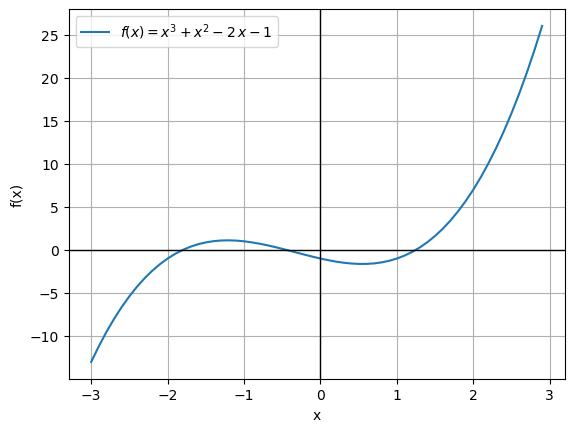

In [2]:
#| code-fold: true
import matplotlib.pyplot as plt
import numpy as np
xs = np.arange(-3, 3, 0.1)
ys = xs**3 + xs**2 - 2 * xs-1
plt.plot(xs, ys, label=r"$f(x)=x^3+x^2-2\,x-1$")

plt.axhline(0, color="black", linewidth=1)  # x-Achse
plt.axvline(0, color="black", linewidth=1)  # y-Achse
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True)

plt.show()

Jetzt implementieren wir das Verfahren:

In [26]:
#| code-fold: true
#| output: false
max_iter = 100  # maximale Zahl der Iterationen
x = 1.0  # Startwert
tol = 1e-6  # Toleranz

for i in range(max_iter):    

    # Funktion:
    f = x**3 + x**2 - 2 * x - 1 

    # Ableitung:
    fp = 3 * x**2 + 2 * x - 2 
    
    if abs(f) < tol:
        # Funktionswert ist nahe genug bei Null
        print("Konvergiert nach ", i, "Iterationen.")
        break
    
    x = x - f / fp  # Iteration des Newton-Verfahrens

if abs(f) >= tol:
    print("Keine Konvergenz nach", max_iter, "Iterationen!")
    
print("x=", x, "f(x)=", f)

Konvergiert nach  4 Iterationen.
x= 1.246979604778425 f(x)= 5.4733053644895335e-09


*Bemerkung*: Eine alternative Abbruchbedingung betrachtet die Änderung in $x$ von Schritt zu Schritt. Sobald sich $x$ nicht mehr signifikant ändert, bricht das Verfahren ab. Wir gehen an dieser Stelle nicht auf die Vor- und Nachteile der jeweiligen Abbruchbedingung ein.

### Lineare Algebra mit Listen {.unnumbered}

Vektoren und Matrizen können mit Python-Listen dargestellt werden. Mithilfe von Schleifen können elementare Operationen der Linearen Algebra programmiert werden. Wir beginnen mit zwei Vektoren:

In [5]:
v = [1.0, -2.0, 1.5] # Vektor v
w = [-1.0, 1.0, 0.5] # Vektor w

#### Vektoraddition {.unnumbered}

In [8]:
v_plus_w = [0,0,0] # Initialisierung

for i in range(3):
    v_plus_w[i] = v[i] + w[i]

print(v_plus_w)

[0.0, -1.0, 2.0]


Was wäre eigentlich geschehen, wenn wir `v + w` ausprobiert hätten? Vergessen Sie nicht, dass `v` und `w` Listen sind und als solche keine natürliche Addition kennen. Stattdessen konkateniert der Plus-Operator die beiden Listen: 

In [11]:
v_concat_w = v + w
print(v_concat_w)  # offensichtlich keine Vektoraddition 

[1.0, -2.0, 1.5, -1.0, 1.0, 0.5]


#### Skalarprodukt {.unnumbered}

Das Skalarprodukt ist eine wichtige Operation in der Linearen Algebra, mit der z.B. überprüft werden kann, ob zwei Vektoren senkrecht aufeinander stehen (Skalarprodukt gleich Null). Implementierung:

In [19]:
v_dot_w = 0  # Initialisierung

for i in range(3):
    v_dot_w += v[i] * w[i]

print(v_dot_w)

-2.25


Solche Schleifen über zwei Listen mit gemeinsamem Index lassen sich mit der Funktion `zip()` noch eleganter schreiben – siehe Abschnitt [-@sec-enumerate-zip] im Kapitel *Datenstrukturen*.

#### Matrizen {.unnumbered}

Eine Matrix kann als verschachtelte Liste dargestellt werden. Man kann sich das so vorstellen, dass die Elemente der äußeren Liste die Zeilen der Matrix sind (jede Zeile ist wiederum eine Liste ihrer Elemente):

In [39]:
# innerhalb der eckigen Klammern sind 
# Zeilenumbrüche erlaubt, was die
# Lesbarkeit als Matrix erhöht:
M = [
    [1.0, 0.0, 1.0],   # erste Zeile
    [0.0, -1.0, 0.0],  # zweite Zeile
    [2.0, 0.0, 0.0]    # dritte Zeile
]
print(M)

[[1.0, 0.0, 1.0], [0.0, -1.0, 0.0], [2.0, 0.0, 0.0]]


Auf die Elemente der Matrix kann über Indizes zugegriffen werden:

In [42]:
M[0]  # ist die erste Zeile
M[0][0]  # erste Zeile, erste Spalte
M[0][1]  # erste Zeile, zweite Spalte
M[0][2]  # erste Zeile, dritte Spalte

print(M[2][0])  # dritte Zeile, erste Spalte

2.0


#### Matrixaddition {.unnumbered}

In [60]:
M = [
    [1.0, 0.0, 1.0],   # erste Zeile
    [0.0, -1.0, 0.0],  # zweite Zeile
    [2.0, 0.0, 0.0]    # dritte Zeile
]

N = [                  
    [1.0, 0.5, 1.0],   # erste Zeile
    [2.0, 1.0, 2.0],  # zweite Zeile
    [-1.0, -1.0, 1.0]    # dritte Zeile
]

In [64]:
M_plus_N = [           # Initialisierung
    [0.0, 0.0, 0.0],   # erste Zeile
    [0.0, 0.0, 0.0],   # zweite Zeile
    [0.0, 0.0, 0.0]    # dritte Zeile
]

for i in range(3):     # i iteriert über die Zeilen
    for j in range(3): # j iteriert über die Spalten
        M_plus_N[i][j] = M[i][j] + N[i][j]

print(M_plus_N)  # überprüfen Sie das Ergebnis

[[2.0, 0.5, 2.0], [2.0, 0.0, 2.0], [1.0, -1.0, 1.0]]


Machen Sie sich die Funktionsweise der verschachtelten for-Schleifen klar: Der *Zeilen*index `i` iteriert von 0 bis 2. Für jede Zeile, also jeden Wert von `i`, startet der *Spalten*index `j` jeweils wieder bei 0 und iteriert bis 2. So wird jede Kombination von `i` und `j` durchlaufen.  

#### Matrix mal Vektor {.unnumbered}

In [87]:
M_dot_v = [0, 0, 0]  # Initialisierung

for i in range(3):
    for j in range(3):
        M_dot_v[i] += M[i][j] * v[j]

print(M_dot_v)  # rechnen Sie nach!

[2.5, 2.0, 2.0]


<div class="exercises">
<b>Übungen:</b>    
    
1. Implementieren Sie die Multiplikation von zwei Matrizen. 
2. Implementieren Sie eine Schleife, die die Transponierte einer Matrix berechnet. 

</div>